# Airport map in the United States and France

## "Static" map

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
ISO_COUNTRY = "iso_country"

US_ISO = "US"
FR_ISO = ["FR", "GF"]

Load the data into a dataframe.

In [3]:
url_airports = "https://davidmegginson.github.io/ourairports-data/airports.csv"
airports = pd.read_csv(url_airports)

In [4]:
airports.head()

,id,ident,type,name,latitude_deg,longitude_deg,elevation_ft,continent,iso_country,iso_region,municipality,scheduled_service,icao_code,iata_code,gps_code,local_code,home_link,wikipedia_link,keywords
0,6523,00A,heliport,Total RF Heliport,40.070985,-74.933689,11.0,NaN,US,US-PA,Bensalem,no,NaN,NaN,K00A,00A,https://www.penndot.pa.gov/TravelInPA/airports...,NaN,NaN
1,323361,00AA,small_airport,Aero B Ranch Airport,38.704022,-101.473911,3435.0,NaN,US,US-KS,Leoti,no,NaN,NaN,00AA,00AA,NaN,NaN,NaN
2,6524,00AK,small_airport,Lowell Field,59.947733,-151.692524,450.0,NaN,US,US-AK,Anchor Point,no,NaN,NaN,00AK,00AK,NaN,NaN,NaN
3,6525,00AL,small_airport,Epps Airpark,34.864799,-86.770302,820.0,NaN,US,US-AL,Harvest,no,NaN,NaN,00AL,00AL,NaN,NaN,NaN
4,506791,00AN,small_airport,Katmai Lodge Airport,59.093287,-156.456699,80.0,NaN,US,US-AK,King Salmon,no,NaN,NaN,00AN,00AN,NaN,NaN,NaN


In [5]:
airports.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83312 entries, 0 to 83311
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 83312 non-null  int64  
 1   ident              83312 non-null  object 
 2   type               83312 non-null  object 
 3   name               83312 non-null  object 
 4   latitude_deg       83312 non-null  float64
 5   longitude_deg      83312 non-null  float64
 6   elevation_ft       68791 non-null  float64
 7   continent          44098 non-null  object 
 8   iso_country        83044 non-null  object 
 9   iso_region         83312 non-null  object 
 10  municipality       78598 non-null  object 
 11  scheduled_service  83312 non-null  object 
 12  icao_code          8868 non-null   object 
 13  iata_code          9069 non-null   object 
 14  gps_code           43419 non-null  object 
 15  local_code         35679 non-null  object 
 16  home_link          432

In [6]:
airports.describe(include="all")

,id,ident,type,name,latitude_deg,longitude_deg,elevation_ft,continent,iso_country,iso_region,municipality,scheduled_service,icao_code,iata_code,gps_code,local_code,home_link,wikipedia_link,keywords
count,83312.000000,83312,83312,83312,83312.000000,83312.000000,68791.000000,44098,83044,83312,78598,83312,8868,9069,43419,35679,4327,16530,20318
unique,NaN,83312,7,78819,NaN,NaN,NaN,6,245,2954,37211,2,8868,9069,43419,34168,4277,16418,19822
top,NaN,00A,small_airport,Centre Hospitalier Heliport,NaN,NaN,NaN,AS,US,US-TX,Osaka,no,HCAD,UTK,K00A,PRO,https://www.fuerzaaerea.mil.py,https://es.wikipedia.org/wiki/Fuerza_Aérea_Par...,Mukho
freq,NaN,1,42268,49,NaN,NaN,NaN,12244,32141,3826,418,78943,1,1,1,5,17,17,48
mean,194969.516516,NaN,NaN,NaN,26.022407,-27.778091,1293.400547,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,190984.347588,NaN,NaN,NaN,26.139746,85.549091,1660.435393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,2.000000,NaN,NaN,NaN,-90.000000,-179.876999,-1266.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,20982.750000,NaN,NaN,NaN,13.203037,-93.386860,210.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,44608.500000,NaN,NaN,NaN,35.204561,-65.747500,728.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,341582.250000,NaN,NaN,NaN,43.099713,23.492133,1601.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
airports["type"].value_counts()

type
small_airport     42268
heliport          21940
closed            12642
medium_airport     4685
seaplane_base      1235
large_airport       485
balloonport          57
Name: count, dtype: int64

Create two dataframes, one for airports in the United States and the other for French airports.

In [8]:
us_airports = airports[airports[ISO_COUNTRY] == US_ISO]
fr_airports = airports[airports[ISO_COUNTRY].isin(FR_ISO)]

Convert the dataframes into GeoDataFrames (longitude, latitude) using geopandas.

In [9]:
gdf_us_airports = gpd.GeoDataFrame(
    us_airports,
    geometry=gpd.points_from_xy(us_airports.longitude_deg, us_airports.latitude_deg),
    crs="EPSG:4326"
)

gdf_fr_airports = gpd.GeoDataFrame(
    fr_airports,
    geometry=gpd.points_from_xy(fr_airports.longitude_deg, fr_airports.latitude_deg),
    crs="EPSG:4326"
)

Using matplotlib, visualize U.S. airports on a map, representing them with red points. Use the fig, ax syntax. Add a title to the plot.

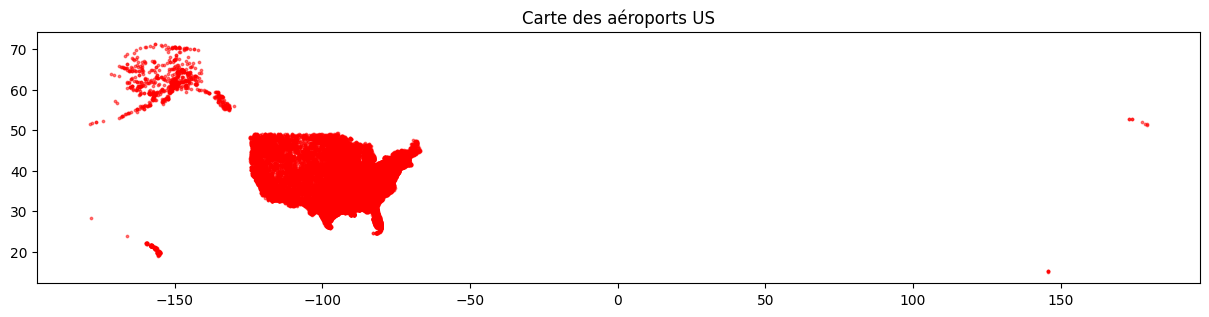

In [10]:
fig, ax = plt.subplots(figsize=(15, 10))
gdf_us_airports.plot(kind="geo", ax=ax, color="red", markersize=3, alpha=0.5)
plt.title("Carte des aéroports US")
plt.show()

Same question with French airports.

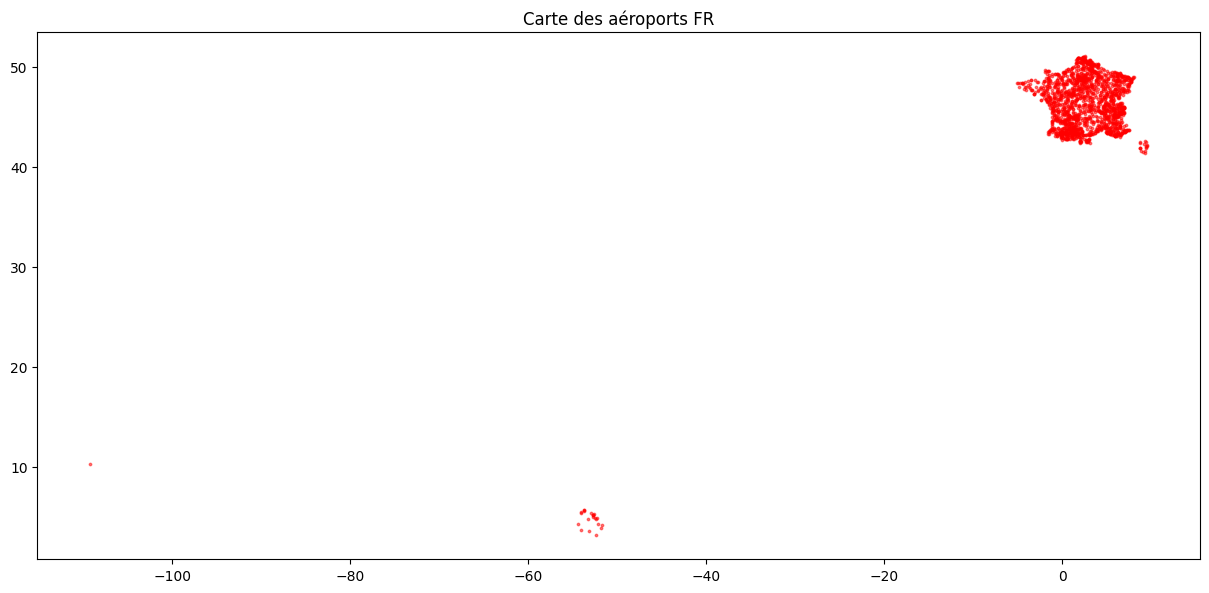

In [11]:
fig, ax = plt.subplots(figsize=(15, 10))
gdf_fr_airports.plot(kind="geo", ax=ax, color="red", markersize=3, alpha=0.5)
plt.title("Carte des aéroports FR")
plt.show()

## Using folium to create visualizations on an interactive map

In [12]:
from pathlib import Path

import folium

In [13]:
DATA_DIR = Path("../../data")
OUTPUT_DIR = Path(DATA_DIR, "output")

Find the coordinates of France to center the map.

In [14]:
latitude_fr = 46
longitude_fr = 2.33
m_fr = folium.Map(location=[latitude_fr, longitude_fr], zoom_start=6)

Add French airports to this map. Represent them this time as green points, with size (radius) 3. Add a popup showing the airport name when clicked.

In [15]:
for idx, row in gdf_fr_airports.iterrows():
    folium.CircleMarker(
        location=[row.latitude_deg, row.longitude_deg],
        fill=True,
        fill_opacity=0.7,
        color="green",
        radius=3,
        popup=(row["name"], row["type"]),
    ).add_to(m_fr)

Display the map in the notebook.

In [16]:
m_fr

Save the map in HTML format.

In [17]:
m_fr.save(Path(OUTPUT_DIR, "fr_airports_folium_map.html"))

Display the map via the HTML file.

Bonus question: visualize "large airports" with markers of different color and size.

In [18]:
latitude_fr = 46
longitude_fr = 2.33
m_fr_2 = folium.Map(location=[latitude_fr, longitude_fr], zoom_start=6)

In [19]:
for idx, row in gdf_fr_airports[gdf_fr_airports["type"] != "large_airport"].iterrows():
    folium.CircleMarker(
        location=[row.latitude_deg, row.longitude_deg],
        fill=True,
        fill_opacity=0.7,
        color="green",
        radius=3,
        popup=(row["name"], row["type"]),
    ).add_to(m_fr_2)

for idx, row in gdf_fr_airports[gdf_fr_airports["type"]== "large_airport"].iterrows():
    folium.CircleMarker(
        location=[row.latitude_deg, row.longitude_deg],
        fill=True,
        fill_opacity=0.7,
        color="red",
        radius=8,
        popup=(row["name"], row["type"]),
    ).add_to(m_fr_2)

In [20]:
m_fr_2

## Using plotly to create visualizations on an interactive map

Note that in addition to plotly, you may need to install or update the nbformat library: <br>
(python -m) pip install --upgrade nbformat

### Plotly express

In [21]:
import plotly.express as px

Prepare the map.

In [22]:
fig = px.scatter_geo(
    gdf_fr_airports,
    lat=gdf_fr_airports.geometry.y,
    lon=gdf_fr_airports.geometry.x,
    color="type",
    hover_name="name",
    projection="natural earth",
    title="Carte des aéroports FR",
    opacity=0.7,
    color_discrete_sequence=px.colors.qualitative.Safe,
)

fig.update_layout(
    geo=dict(
        scope="europe",
        showland=True,
        landcolor="rgb(243, 243, 243)",
        countrycolor="rgb(204, 204, 204)",
    )
)

Display the map.

In [23]:
fig.show()

Export the map in HTML format. If needed, find the syntax in the plotly documentation or online ;)

In [24]:
fig.write_html(Path(OUTPUT_DIR, "fr_airports_plotly_map.html"))

### Plotly graph objects

In [25]:
import plotly.graph_objects as go

Instantiate an empty figure.

In [26]:
fig = go.Figure()

Add to this figure the airports of type "large_airport" in red (starting directly from the differentiated GeoDataFrames).

In [27]:
fig.add_trace(go.Scattergeo(
    lat=gdf_fr_airports[gdf_fr_airports["type"] == "large_airport"].geometry.y,
    lon=gdf_fr_airports[gdf_fr_airports["type"] == "large_airport"].geometry.x,
    text=gdf_fr_airports[gdf_fr_airports["type"] == "large_airport"]["name"],
    mode="markers",
    marker=dict(
        size=8,
        color="red",
        opacity=0.8,
        symbol="circle",
    ),
    name="Large FR airports"
))

Add the other airports.

In [28]:
fig.add_trace(go.Scattergeo(
    lat=gdf_fr_airports[gdf_fr_airports["type"] != "large_airport"].geometry.y,
    lon=gdf_fr_airports[gdf_fr_airports["type"] != "large_airport"].geometry.x,
    text=gdf_fr_airports[gdf_fr_airports["type"] != "large_airport"]["name"],
    mode="markers",
    marker=dict(
        size=3,
        color="green",
        opacity=0.8,
        symbol="circle"
    ),
    name="Other FR airports"
))

Configure the map.

In [31]:
fig.update_layout(
    title="FR airports",
    geo=dict(
        scope='europe',
        projection_type='natural earth',
        showland=True,
        landcolor='rgb(243, 243, 243)',
        countrycolor='rgb(204, 204, 204)',
        lataxis=dict(range=[41, 52]),
        lonaxis=dict(range=[-5, 10])
    ),
    legend=dict(x=0.8, y=0.1)
)

Display the map.

In [32]:
fig.show()

Save the map in HTML format.

In [34]:
fig.write_html(Path(OUTPUT_DIR, "fr_airports_plotly_go_map.html"))